In [1]:
import numpy as np
import pandas as pd

# dataset
df = pd.read_csv("previousApplicants.csv")

# first 5 rows
df.head()

,ID,Age,Income,Postcode,Gender,Outgoings,Approved
0,456723624.0,76.0,116014,WA7 1SJ,b,12732.0,True
1,456723677.0,29.0,119177,WS10 9BG,b,1211.0,True
2,456723829.0,81.0,142052,SW1V 3HS,b,816.0,True
3,456723872.0,24.0,43451,DE24 8GN,b,21794.0,False
4,456723973.0,25.0,54961,BR4 0HL,a,22791.0,False


In [2]:
# Number of rows and columns
print("Shape of Dataset:", df.shape)

# Display column names
print("\nColumns:")
print(df.columns)

# Display data types
print("\nData Types:")
print(df.dtypes)

Shape of Dataset: (13734, 7)

Columns:
Index(['ID', 'Age', 'Income', 'Postcode', 'Gender', 'Outgoings', 'Approved'], dtype='object')

Data Types:
ID           float64
Age          float64
Income        object
Postcode      object
Gender        object
Outgoings    float64
Approved      object
dtype: object


In [3]:
# Information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13734 entries, 0 to 13733
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         13500 non-null  float64
 1   Age        13500 non-null  float64
 2   Income     13500 non-null  object 
 3   Postcode   13500 non-null  object 
 4   Gender     13500 non-null  object 
 5   Outgoings  13731 non-null  float64
 6   Approved   13731 non-null  object 
dtypes: float64(3), object(4)
memory usage: 751.2+ KB


In [4]:
# Summary of numerical columns
df.describe()

,ID,Age,Outgoings
count,1.350000e+04,13500.000000,1.373100e+04
mean,4.573485e+08,57.413407,4.573593e+22
std,3.612742e+05,23.007830,2.089194e+23
min,4.567236e+08,18.000000,6.000000e+02
25%,4.570352e+08,37.000000,7.118500e+03
50%,4.573487e+08,58.000000,1.349200e+04
75%,4.576614e+08,77.000000,1.973550e+04
max,4.579736e+08,96.000000,1.000000e+24


In [5]:
# Count missing values in each column
print(df.isnull().sum())

ID           234
Age          234
Income       234
Postcode     234
Gender       234
Outgoings      3
Approved       3
dtype: int64


In [6]:
# Count duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 231


In [7]:
# Check how many approved and rejected applications are present
print(df["Approved"].value_counts())

Approved
True     8021
False    5710
Name: count, dtype: int64


In [8]:
# Check unique values in Gender

print(df["Gender"].value_counts(dropna=False))

Gender
a      6785
b      6714
NaN     234
c         1
Name: count, dtype: int64


# EDA

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

## Distribution of Loan Approval

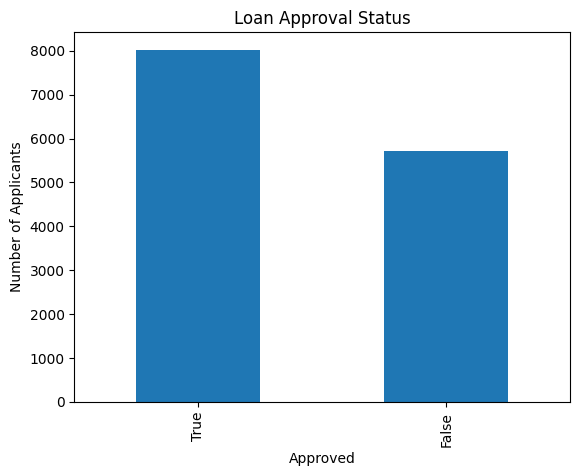

In [10]:
# Count approved and rejected applications

df["Approved"].value_counts().plot(kind="bar")

plt.title("Loan Approval Status")
plt.xlabel("Approved")
plt.ylabel("Number of Applicants")
plt.show()

## Age Distribution

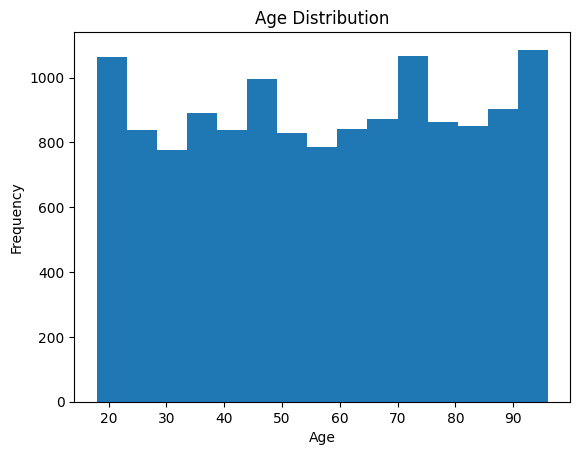

In [11]:
# Distribution of applicants' age

plt.hist(df["Age"], bins=15)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

## Gender Distribution

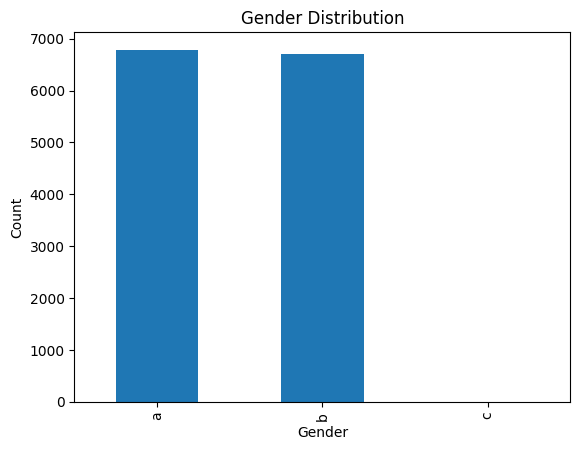

In [12]:
# Number of male and female applicants

df["Gender"].value_counts().plot(kind="bar")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

## Outgoings Distribution

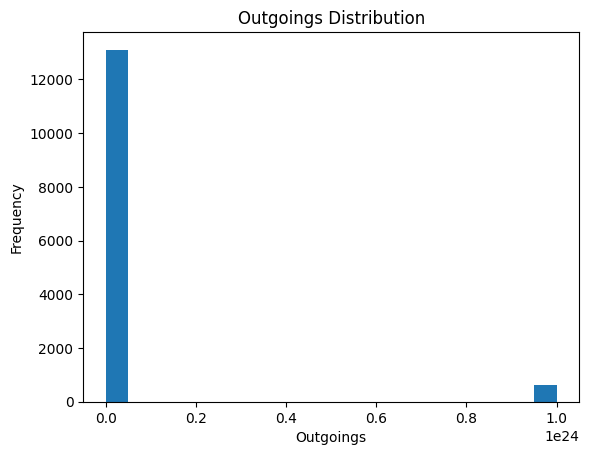

In [13]:
# Distribution of monthly outgoings

plt.hist(df["Outgoings"], bins=20)

plt.title("Outgoings Distribution")
plt.xlabel("Outgoings")
plt.ylabel("Frequency")
plt.show()

## Approval by Gender

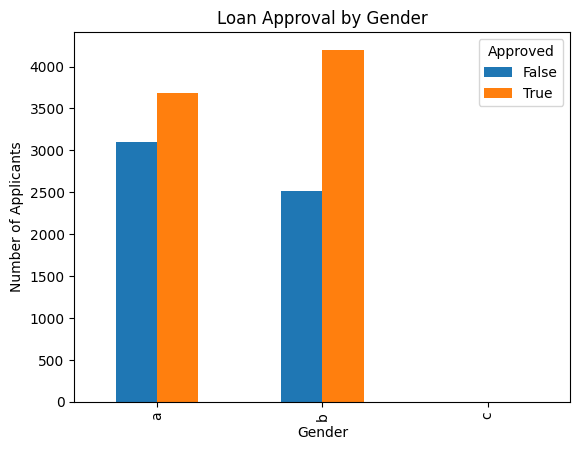

In [14]:
# Compare loan approval based on gender

pd.crosstab(df["Gender"], df["Approved"]).plot(kind="bar")

plt.title("Loan Approval by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Applicants")
plt.show()

## Correlation Between Numerical Features

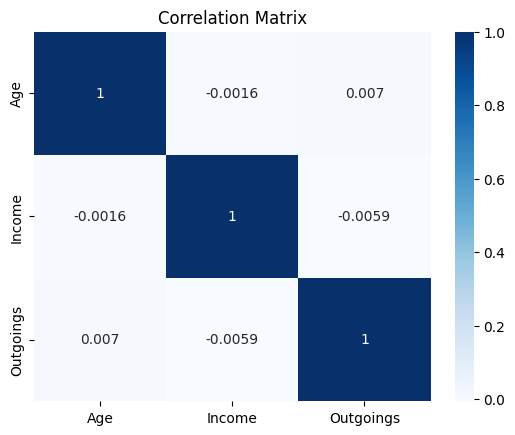

In [15]:
# Convert Income to numeric

df["Income"] = pd.to_numeric(df["Income"], errors="coerce")

# Correlation heatmap

corr = df[["Age", "Income", "Outgoings"]].corr()

sns.heatmap(corr, annot=True, cmap="Blues")

plt.title("Correlation Matrix")
plt.show()

# Data Cleaning

In [16]:
# Remove duplicate records
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)


Shape after removing duplicates: (13503, 7)


In [17]:
# Remove ID column (not useful for prediction)
df = df.drop("ID", axis=1)


# Remove invalid gender value ('c')
df = df[df["Gender"] != "c"]


# Convert Income column to numeric
df["Income"] = pd.to_numeric(df["Income"], errors="coerce")




In [18]:
# Check missing values
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())


Missing Values Before Cleaning:
Age            3
Income       606
Postcode       3
Gender         3
Outgoings      1
Approved       1
dtype: int64


In [19]:
# handle missing values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Income"] = df["Income"].fillna(df["Income"].median())
df["Outgoings"] = df["Outgoings"].fillna(df["Outgoings"].median())

df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])
df["Postcode"] = df["Postcode"].fillna(df["Postcode"].mode()[0])
df["Approved"] = df["Approved"].fillna(df["Approved"].mode()[0]).infer_objects(copy=False)


# Remove unrealistic Outgoings values
df = df[df["Outgoings"] <= 100000]


# Reset index
df = df.reset_index(drop=True)


# Check missing values after cleaning
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


Missing Values After Cleaning:
Age          0
Income       0
Postcode     0
Gender       0
Outgoings    0
Approved     0
dtype: int64


/tmp/ipykernel_22106/827788251.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Approved"] = df["Approved"].fillna(df["Approved"].mode()[0]).infer_objects(copy=False)


In [20]:
print("\nDataset Shape After Cleaning:", df.shape)

df.head()


Dataset Shape After Cleaning: (13103, 6)


,Age,Income,Postcode,Gender,Outgoings,Approved
0,76.0,116014.0,WA7 1SJ,b,12732.0,True
1,29.0,119177.0,WS10 9BG,b,1211.0,True
2,81.0,142052.0,SW1V 3HS,b,816.0,True
3,24.0,43451.0,DE24 8GN,b,21794.0,False
4,25.0,54961.0,BR4 0HL,a,22791.0,False


# Data Preprocessing

In [21]:
# Remove Postcode column

df = df.drop("Postcode", axis=1)

df.head()

,Age,Income,Gender,Outgoings,Approved
0,76.0,116014.0,b,12732.0,True
1,29.0,119177.0,b,1211.0,True
2,81.0,142052.0,b,816.0,True
3,24.0,43451.0,b,21794.0,False
4,25.0,54961.0,a,22791.0,False


In [22]:
from sklearn.preprocessing import LabelEncoder

# Create encoder
le = LabelEncoder()

# Encode Gender
df["Gender"] = le.fit_transform(df["Gender"])

# Encode Approved (Target)
df["Approved"] = le.fit_transform(df["Approved"])

df.head()

,Age,Income,Gender,Outgoings,Approved
0,76.0,116014.0,1,12732.0,1
1,29.0,119177.0,1,1211.0,1
2,81.0,142052.0,1,816.0,1
3,24.0,43451.0,1,21794.0,0
4,25.0,54961.0,0,22791.0,0


In [23]:
# Features
X = df.drop("Approved", axis=1)

# Target
y = df["Approved"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (13103, 4)
Target Shape: (13103,)


In [24]:
from sklearn.model_selection import train_test_split

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (10482, 4)
Testing Data: (2621, 4)


In [25]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Scale the training data
X_train = scaler.fit_transform(X_train)

# Scale the testing data
X_test = scaler.transform(X_test)

# Model 1: Logistic Regression

In [26]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [27]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the model
lr = LogisticRegression(random_state=42)

# Train the model
lr.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr.predict(X_test)

In [28]:
# code adapted from (How to compute precision,recall and f1 score of an balanced logistic regression model in python, 2022)

print("Logistic Regression Performance")
print()

print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1 Score :", f1_score(y_test, y_pred_lr))

# end of adapted code

Logistic Regression Performance

Accuracy : 0.6486074017550553
Precision: 0.6740867579908676
Recall   : 0.7713912475506205
F1 Score : 0.719463904964971


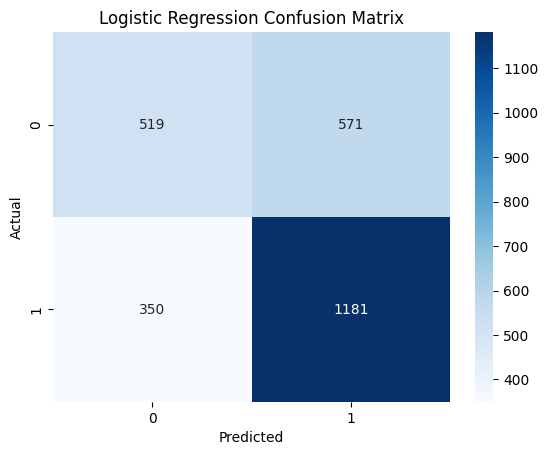

In [29]:
cm = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [30]:
print("Logistic Regression Classification Report")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       0.60      0.48      0.53      1090
           1       0.67      0.77      0.72      1531

    accuracy                           0.65      2621
   macro avg       0.64      0.62      0.62      2621
weighted avg       0.64      0.65      0.64      2621



# Model 2: Decision Tree

In [31]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

In [32]:
print("Decision Tree Performance")
print()

print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall   :", recall_score(y_test, y_pred_dt))
print("F1 Score :", f1_score(y_test, y_pred_dt))

Decision Tree Performance

Accuracy : 0.5967188096146508
Precision: 0.6616643929058663
Recall   : 0.6335728282168517
F1 Score : 0.6473139806473139


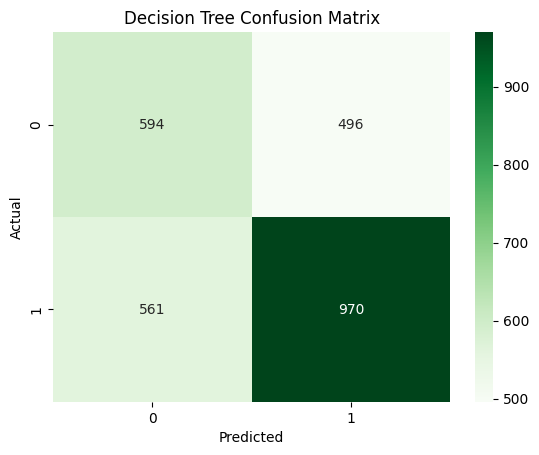

In [33]:
cm = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Greens")

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [34]:
print("Decision Tree Classification Report")
print(classification_report(y_test, y_pred_dt))

Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.51      0.54      0.53      1090
           1       0.66      0.63      0.65      1531

    accuracy                           0.60      2621
   macro avg       0.59      0.59      0.59      2621
weighted avg       0.60      0.60      0.60      2621



# Model 3: Random Forest

In [35]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [36]:
print("Random Forest Performance")
print()

print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))

Random Forest Performance

Accuracy : 0.656619610835559
Precision: 0.6881335718545021
Recall   : 0.7537557152188112
F1 Score : 0.7194513715710723


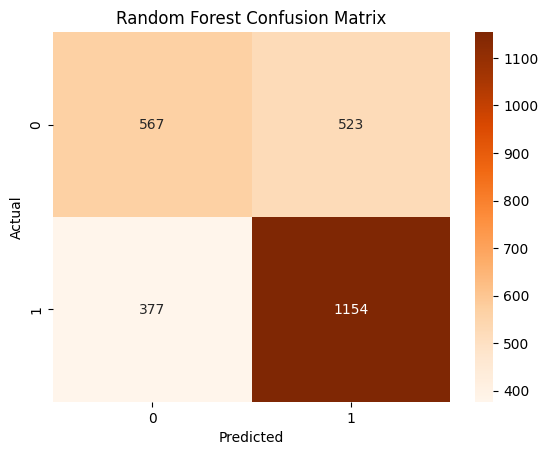

In [37]:
cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Oranges")

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [38]:
print("Random Forest Classification Report")
print(classification_report(y_test, y_pred_rf))

Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.60      0.52      0.56      1090
           1       0.69      0.75      0.72      1531

    accuracy                           0.66      2621
   macro avg       0.64      0.64      0.64      2621
weighted avg       0.65      0.66      0.65      2621



# Comparision between models

In [39]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.648607   0.674087  0.771391  0.719464
1        Decision Tree  0.596719   0.661664  0.633573  0.647314
2        Random Forest  0.656620   0.688134  0.753756  0.719451
